# DSAI Club Induction 2026 — Toxic Comment Classification

Predict six independent toxicity probabilities for every test comment. A comment can have none, one, or several labels, so the solution uses six binary logistic-regression classifiers.

The evaluation metric is the unweighted mean of the six column-wise ROC AUC scores. Submit continuous probabilities in the original test ID order.

The selected architecture combines up to 80,000 word TF-IDF features and 60,000 character TF-IDF features with balanced class weights and a fixed C for each label. The saved experiment outputs recorded a holdout mean AUC of **0.987235**. 
Validation uses a fixed 90% training and 10% validation split with random seed 42, stratified by whether a comment has any toxicity label. TF-IDF is fitted only on the training portion. The reported score is the unweighted mean of the six label-wise ROC AUC scores. Because this split was reused for parameter selection, 0.987235 is a model-selection validation score.

Word bigrams represent short phrases, while character n-grams represent spelling variants and partial words. Balanced class weights give minority examples more influence during training. Combining these features with per-label regularization improved validation mean AUC from approximately **0.978086** for the baseline to **0.987235**. The selected configuration is then retrained on all labelled rows to generate test probabilities.

## 1. Imports and fixed configuration

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_auc_score

PARAMETER_LIMIT = 1_000_000
WORD_FEATURE_BUDGET = 80_000
CHAR_FEATURE_BUDGET = 60_000
C_VALUES = [0.25, 0.5, 1.0, 2.0, 4.0]
c_results = []
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
RANDOM_STATE = 42
TRAIN_PATH = '/kaggle/input/competitions/dsai-club-induction-2026-sy-task/competition_train.csv'
TEST_PATH  = '/kaggle/input/competitions/dsai-club-induction-2026-sy-task/competition_test.csv'

## 2. Load the official training and test data

In [2]:
train = pd.read_csv(TRAIN_PATH)
test  = pd.read_csv(TEST_PATH)

print("train shape: ", train.shape)
print("test shape:  ", test.shape)
print("train columns:", train.columns.tolist())
print("test columns: ", test.columns.tolist())
train.head()


train shape:  (127657, 8)
test shape:   (31914, 2)
train columns: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
test columns:  ['id', 'comment_text']


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,dsai000000,"""The citation for the point """"It helped setup ...",0,0,0,0,0,0
1,dsai000001,What i'm talking about are edits such as this ...,0,0,0,0,0,0
2,dsai000002,March 2008 \n Please stop. If you continue to ...,0,0,0,0,0,0
3,dsai000003,"""\nE. J. Thribb2\n\nSo. Farewell then\nMalleus...",1,0,1,0,1,0
4,dsai000004,"Sorry dude, but that's just the way the Wikipe...",0,0,0,0,0,0


## 3. Check missing values, labels, and ID overlap

In [3]:
print("train missing values:\n", train.isnull().sum())
print("test missing values:\n",  test.isnull().sum())
train["comment_text"] = train["comment_text"].fillna("")
test["comment_text"]  = test["comment_text"].fillna("")

print("Values that are not 0 or 1:")
print(train[(train[LABELS] != 0) & (train[LABELS] != 1)].sum().sum())

print("Train/Test id overlap: ", len(set(train["id"]) & set(test["id"])))

train missing values:
 id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64
test missing values:
 id              0
comment_text    0
dtype: int64
Values that are not 0 or 1:
0.0
Train/Test id overlap:  0


## 4. Explore label distribution

Positive counts per label:
 toxic            12304
obscene           6797
insult            6291
severe_toxic      1271
identity_hate     1154
threat             383
dtype: int64

Percentage positive per label:
 toxic            9.638
severe_toxic     0.996
obscene          5.324
threat           0.300
insult           4.928
identity_hate    0.904
dtype: float64


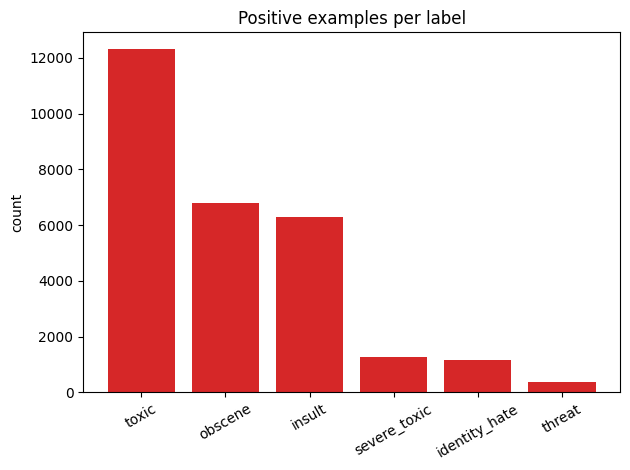

In [4]:
counts = train[LABELS].sum().sort_values(ascending=False)

print("Positive counts per label:\n", counts)
print("\nPercentage positive per label:\n", (100 * train[LABELS].mean()).round(3))

plt.bar(counts.index, counts.values, color="tab:red")
plt.title("Positive examples per label")
plt.ylabel("count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 5. Explore label overlap and correlation

Labels per comment:
 0    114604
1      5131
2      2815
3      3349
4      1423
5       310
6        25
Name: count, dtype: int64


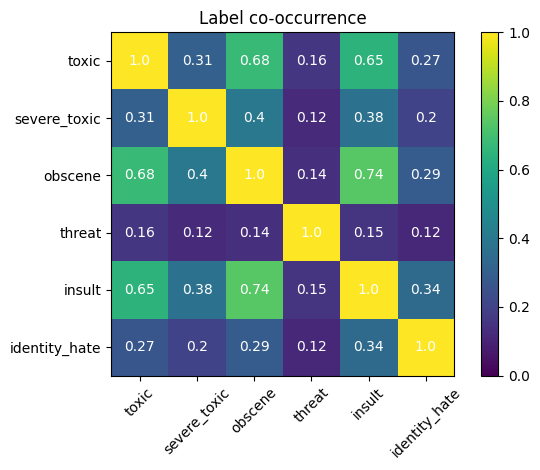

In [5]:
n_labels = train[LABELS].sum(axis=1)
train["any_toxic"] = (n_labels > 0).astype(int)

print("Labels per comment:\n", n_labels.value_counts().sort_index())

corr = train[LABELS].corr()
plt.imshow(corr, cmap="viridis", vmin=0, vmax=1)
plt.xticks(range(len(LABELS)), LABELS, rotation=45)
plt.yticks(range(len(LABELS)), LABELS)

for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        plt.text(j, i, round(corr.iloc[i, j], 2),
                 ha="center", va="center", color="white")

plt.title("Label co-occurrence")
plt.colorbar()
plt.tight_layout()
plt.show()


## 6. Explore comment length

              count        mean         std  min    25%    50%    75%     max
any_toxic                                                                    
0          114604.0  403.794876  587.886574  6.0  101.0  215.0  451.0  5000.0
1           13053.0  302.580250  611.481675  8.0   61.0  129.0  284.0  5000.0


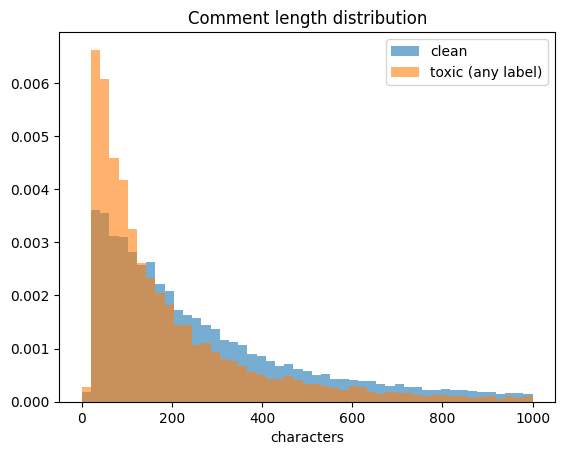

In [6]:
train["n_chars"] = train["comment_text"].str.len()
print(train.groupby("any_toxic")["n_chars"].describe())

bins = np.linspace(0, 1000, 50)
plt.hist(train.loc[train["any_toxic"] == 0, "n_chars"],
         bins=bins, alpha=0.6, label="clean", density=True)
plt.hist(train.loc[train["any_toxic"] == 1, "n_chars"],
         bins=bins, alpha=0.6, label="toxic (any label)", density=True)
plt.title("Comment length distribution")
plt.xlabel("characters")
plt.legend()
plt.show()


## 7. Top words in TOXIC and CLEAN Comments

In [7]:
train.loc[n_labels > 0, ["comment_text"] + LABELS].head(5)

def top_words(texts, n=15):
    counter = Counter()
    for t in texts:
        counter.update(w for w in re.findall(r"[a-z']+", t.lower()) if len(w) > 3)
    return counter.most_common(n)

toxic_sample = train.loc[train["any_toxic"] == 1, "comment_text"].sample(
    min(20000, (train["any_toxic"] == 1).sum()), random_state=RANDOM_STATE)
clean_sample = train.loc[train["any_toxic"] == 0, "comment_text"].sample(
    20000, random_state=RANDOM_STATE)
print("Top words in TOXIC comments:", top_words(toxic_sample))
print("Top words in CLEAN comments:", top_words(clean_sample))


Top words in TOXIC comments: [('your', 7479), ('fuck', 7242), ('that', 7147), ('this', 4685), ('have', 4146), ('with', 3573), ('shit', 3328), ('wikipedia', 3211), ('like', 3205), ('what', 3048), ('nigger', 2821), ('fucking', 2591), ('will', 2502), ('suck', 2492), ('just', 2252)]
Top words in CLEAN comments: [('that', 20555), ('this', 12845), ('have', 9400), ('with', 7797), ('your', 7695), ('article', 7626), ('page', 5997), ('wikipedia', 5788), ('from', 5569), ('about', 4994), ('talk', 4955), ('what', 4321), ('there', 4294), ('please', 4013), ('would', 3979)]


## 8. Create 90% training / 10% validation split

In [8]:
df_tr, df_val = train_test_split(
    train,
    test_size=0.10,
    random_state=RANDOM_STATE,
    stratify=train["any_toxic"],
)

print("Train split: ",len(df_tr), " Validation split: ",len(df_val))
print("Validation positives per label:\n", df_val[LABELS].sum())


Train split:  114891  Validation split:  12766
Validation positives per label:
 toxic            1216
severe_toxic      107
obscene           681
threat             42
insult            605
identity_hate      83
dtype: int64


## 9. Calculate per-label and mean ROC AUC

In [9]:
def evaluate(y_true_df, proba, name="model"):
    scores = {}
    for i, lab in enumerate(LABELS):
        scores[lab] = roc_auc_score(y_true_df[lab], proba[:, i])
    mean_auc = np.mean(list(scores.values()))
    print(name)
    for lab in LABELS:
        print(lab, "AUC =", round(scores[lab], 5))
    print("Mean AUC =", round(mean_auc, 5))
    return scores, mean_auc

## 10. Train and evaluate the baseline

In [10]:
vec = TfidfVectorizer(max_features=50_000)  

X_tr  = vec.fit_transform(df_tr["comment_text"])   
X_val = vec.transform(df_val["comment_text"])      

baseline_clf = OneVsRestClassifier(
    LogisticRegression(max_iter=1000, solver="liblinear", random_state=RANDOM_STATE), n_jobs=-1,)
baseline_clf.fit(X_tr, df_tr[LABELS].values)

val_proba_base = baseline_clf.predict_proba(X_val)
_, baseline_auc = evaluate(df_val, val_proba_base, "BASELINE: word TF-IDF + LogReg")


BASELINE: word TF-IDF + LogReg
toxic AUC = 0.96881
severe_toxic AUC = 0.98519
obscene AUC = 0.97438
threat AUC = 0.98644
insult AUC = 0.97073
identity_hate AUC = 0.98297
Mean AUC = 0.97809


## 11. Word and character TF-IDF with per-label C tuning

| Stage | Holdout mean ROC AUC |
| --- | ---: |
| Word-unigram baseline | 0.978086 |
| Word + character TF-IDF, shared C=1 | 0.986250 |
| Word + character TF-IDF, per-label C, unweighted | 0.986553 |
| Balanced weights with the previous C values | 0.987026 |
| Balanced weights with retuned per-label C | **0.987235** |

The unweighted C values were toxic=1, severe_toxic=0.5, obscene=2, threat=4, insult=1, and identity_hate=1. Both C searches tested 0.25, 0.5, 1, 2, and 4. The final choices were toxic=1, severe_toxic=0.25, obscene=1, threat=2, insult=1, and identity_hate=0.5.

In [11]:
word_vec = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.99,
    sublinear_tf=True,
    strip_accents="unicode",
    max_features=WORD_FEATURE_BUDGET,
    dtype=np.float32,
)

char_vec = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=3,
    max_df=0.999,
    sublinear_tf=True,
    max_features=CHAR_FEATURE_BUDGET,
    dtype=np.float32,
)

X_tr_imp = hstack([
    word_vec.fit_transform(df_tr["comment_text"]),
    char_vec.fit_transform(df_tr["comment_text"]),
]).tocsr()

X_val_imp = hstack([
    word_vec.transform(df_val["comment_text"]),
    char_vec.transform(df_val["comment_text"]),
]).tocsr()

print("Improved feature matrix shape:", X_tr_imp.shape)

estimated_parameters = (
    len(LABELS) * (X_tr_imp.shape[1] + 1)
    + word_vec.idf_.size
    + char_vec.idf_.size
)

assert estimated_parameters <= PARAMETER_LIMIT, (
    "Parameter limit exceeded: " + str(estimated_parameters)
)


def make_label_classifier(C):
    return LogisticRegression(
        C=float(C),
        max_iter=2000,
        solver="liblinear",
        random_state=RANDOM_STATE,
    )


def predict_label_probabilities(models, features):
    label_probabilities = []

    for label in LABELS:
        model = models[label]
        positive_column = list(model.classes_).index(1)
        probabilities = model.predict_proba(features)[:, positive_column]
        label_probabilities.append(probabilities)

    return np.column_stack(label_probabilities)


def c_sort_order(value):
    distance_from_one = abs(np.log(value))
    return distance_from_one, value


assert 1.0 in C_VALUES, "Include C=1.0 for the shared-C reference."

ordered_c_values = sorted(C_VALUES, key=c_sort_order)

c_results = []
best_c_by_label = {}
improved_clf = {}

shared_c1_proba = np.zeros(
    (len(df_val), len(LABELS)),
    dtype=np.float64,
)

for label_index, label in enumerate(LABELS):
    assert set(df_tr[label].unique()) == {0, 1}, (
        label + ": training split must contain both classes."
    )

    assert set(df_val[label].unique()) == {0, 1}, (
        label + ": validation split must contain both classes for ROC AUC."
    )

    best_label_auc = -np.inf
    best_label_model = None
    best_label_c = None

    for C in ordered_c_values:
        candidate = make_label_classifier(C)
        candidate.fit(X_tr_imp, df_tr[label].to_numpy())

        positive_column = list(candidate.classes_).index(1)
        probabilities = candidate.predict_proba(X_val_imp)[:, positive_column]

        label_auc = roc_auc_score(df_val[label], probabilities)

        c_results.append({
            "label": label,
            "C": float(C),
            "auc": label_auc,
        })

        if C == 1.0:
            shared_c1_proba[:, label_index] = probabilities

        if label_auc > best_label_auc:
            best_label_auc = label_auc
            best_label_c = float(C)
            best_label_model = candidate

    best_c_by_label[label] = best_label_c
    improved_clf[label] = best_label_model

    print(
        label,
        "| Selected C:", best_label_c,
        "| AUC:", round(best_label_auc, 6),
    )

c_results = pd.DataFrame(c_results)

validation_auc_table = c_results.pivot(
    index="label",
    columns="C",
    values="auc",
)
validation_auc_table = validation_auc_table.reindex(LABELS)

print("\nValidation AUC for every label and C:")
display(validation_auc_table.round(6))

selected_c_values = []

for label in LABELS:
    selected_c_values.append(best_c_by_label[label])

selected_c_table = pd.DataFrame({
    "label": LABELS,
    "selected_C": selected_c_values,
})

print("\nSelected C values:")
display(selected_c_table)

_, shared_c1_auc = evaluate(
    df_val,
    shared_c1_proba,
    "REFERENCE: shared C=1",
)

val_proba_imp = predict_label_probabilities(
    improved_clf,
    X_val_imp,
)

_, improved_auc = evaluate(
    df_val,
    val_proba_imp,
    "IMPROVED: word + character TF-IDF, per-label C",
)

print("Per-label C mean AUC:", round(improved_auc, 6))
print("Gain vs shared C=1:", round(improved_auc - shared_c1_auc, 6))
print("Gain vs baseline:", round(improved_auc - baseline_auc, 6))
print("Conservative parameter count:", estimated_parameters)

Improved feature matrix shape: (114891, 140000)
toxic | Selected C: 1.0 | AUC: 0.97918
severe_toxic | Selected C: 0.5 | AUC: 0.9884
obscene | Selected C: 2.0 | AUC: 0.987479
threat | Selected C: 4.0 | AUC: 0.99396
insult | Selected C: 1.0 | AUC: 0.980721
identity_hate | Selected C: 1.0 | AUC: 0.989582

Validation AUC for every label and C:


C,0.25,0.50,1.00,2.00,4.00
label,,,,,
toxic,0.975199,0.977964,0.979180,0.979155,0.978189
severe_toxic,0.987731,0.988400,0.988272,0.987154,0.984817
obscene,0.982184,0.985013,0.986744,0.987479,0.987158
threat,0.989385,0.991675,0.993000,0.993705,0.993960
insult,0.978523,0.980115,0.980721,0.980410,0.979085
identity_hate,0.987124,0.988859,0.989582,0.989428,0.988657



Selected C values:


,label,selected_C
0,toxic,1.0
1,severe_toxic,0.5
2,obscene,2.0
3,threat,4.0
4,insult,1.0
5,identity_hate,1.0


REFERENCE: shared C=1
toxic AUC = 0.97918
severe_toxic AUC = 0.98827
obscene AUC = 0.98674
threat AUC = 0.993
insult AUC = 0.98072
identity_hate AUC = 0.98958
Mean AUC = 0.98625
IMPROVED: word + character TF-IDF, per-label C
toxic AUC = 0.97918
severe_toxic AUC = 0.9884
obscene AUC = 0.98748
threat AUC = 0.99396
insult AUC = 0.98072
identity_hate AUC = 0.98958
Mean AUC = 0.98655
Per-label C mean AUC: 0.986553
Gain vs shared C=1: 0.000304
Gain vs baseline: 0.008467
Conservative parameter count: 980006


## 12. Compare balanced class weights

In [12]:
from sklearn.base import clone

reference_models = improved_clf
reference_probabilities = []

for label in LABELS:
    model = reference_models[label]
    positive_column = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_val_imp)[:, positive_column]
    reference_probabilities.append(probabilities)

reference_proba = np.column_stack(reference_probabilities)

balanced_models = {}
balanced_proba = np.zeros(
    (len(df_val), len(LABELS)),
    dtype=np.float64,
)

for i, label in enumerate(LABELS):
    reference_model = reference_models[label]

    assert reference_model.class_weight is None, (
        label + " already uses class weights; check the reference model."
    )

    model = clone(reference_model)
    model.set_params(class_weight="balanced")
    model.fit(X_tr_imp, df_tr[label].to_numpy())

    positive_column = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_val_imp)[:, positive_column]

    balanced_proba[:, i] = probabilities
    balanced_models[label] = model

    print("Finished", label, "| C:", model.C)

reference_scores = roc_auc_score(
    df_val[LABELS].to_numpy(),
    reference_proba,
    average=None,
)

balanced_scores = roc_auc_score(
    df_val[LABELS].to_numpy(),
    balanced_proba,
    average=None,
)

selected_c_values = []

for label in LABELS:
    selected_c_values.append(reference_models[label].C)

weight_comparison = pd.DataFrame({
    "label": LABELS,
    "C": selected_c_values,
    "current_auc": reference_scores,
    "balanced_auc": balanced_scores,
    "change": balanced_scores - reference_scores,
})

display(weight_comparison.round(6))

current_mean_auc = reference_scores.mean()
balanced_mean_auc = balanced_scores.mean()
mean_change = balanced_mean_auc - current_mean_auc

print("Current mean AUC:", round(current_mean_auc, 6))
print("Balanced mean AUC:", round(balanced_mean_auc, 6))
print("Mean change:", round(mean_change, 6))

candidate_parameters = 0

for model in balanced_models.values():
    candidate_parameters += model.coef_.size
    candidate_parameters += model.intercept_.size

candidate_parameters += word_vec.idf_.size
candidate_parameters += char_vec.idf_.size

print("Candidate parameters:", candidate_parameters)

assert candidate_parameters <= PARAMETER_LIMIT

Finished toxic | C: 1.0
Finished severe_toxic | C: 0.5
Finished obscene | C: 2.0
Finished threat | C: 4.0
Finished insult | C: 1.0
Finished identity_hate | C: 1.0


,label,C,current_auc,balanced_auc,change
0,toxic,1.0,0.979180,0.979500,0.000320
1,severe_toxic,0.5,0.988400,0.988154,-0.000246
2,obscene,2.0,0.987479,0.988276,0.000797
3,threat,4.0,0.993960,0.994332,0.000372
4,insult,1.0,0.980721,0.982036,0.001316
5,identity_hate,1.0,0.989582,0.989857,0.000275


Current mean AUC: 0.986553
Balanced mean AUC: 0.987026
Mean change: 0.000473
Candidate parameters: 980006


## 13. Retune C for each balanced classifier

In [13]:
from sklearn.base import clone

BALANCED_C_VALUES = [0.25, 0.5, 1.0, 2.0, 4.0]

balanced_c_results = []
balanced_c_models = {}
balanced_c_by_label = {}

balanced_c_proba = np.zeros(
    (len(df_val), len(LABELS)),
    dtype=np.float64,
)

for i, label in enumerate(LABELS):
    reference_model = balanced_models[label]
    reference_C = float(reference_model.C)

    positive_column = list(reference_model.classes_).index(1)
    reference_probabilities = reference_model.predict_proba(
        X_val_imp
    )[:, positive_column]

    best_auc = roc_auc_score(
        df_val[label],
        reference_probabilities,
    )
    best_model = reference_model
    best_probabilities = reference_probabilities

    candidate_values = sorted(
        set(BALANCED_C_VALUES + [reference_C])
    )

    for C in candidate_values:
        if C == reference_C:
            model = reference_model
            probabilities = reference_probabilities
        else:
            model = clone(reference_model)
            model.set_params(C=C)
            model.fit(X_tr_imp, df_tr[label].to_numpy())

            positive_column = list(model.classes_).index(1)
            probabilities = model.predict_proba(
                X_val_imp
            )[:, positive_column]

        auc = roc_auc_score(df_val[label], probabilities)

        balanced_c_results.append({
            "label": label,
            "C": C,
            "auc": auc,
        })

        if auc > best_auc:
            best_auc = auc
            best_model = model
            best_probabilities = probabilities

    balanced_c_models[label] = best_model
    balanced_c_by_label[label] = float(best_model.C)
    balanced_c_proba[:, i] = best_probabilities

    print(
        label,
        "| Previous C:", reference_C,
        "| Selected C:", best_model.C,
        "| AUC:", round(best_auc, 6),
    )

balanced_c_results = pd.DataFrame(balanced_c_results)

balanced_auc_table = balanced_c_results.pivot(
    index="label",
    columns="C",
    values="auc",
)
balanced_auc_table = balanced_auc_table.reindex(LABELS)

print("\nBalanced validation AUC by label and C:")
display(balanced_auc_table.round(6))

before_scores = roc_auc_score(
    df_val[LABELS].to_numpy(),
    balanced_proba,
    average=None,
)

after_scores = roc_auc_score(
    df_val[LABELS].to_numpy(),
    balanced_c_proba,
    average=None,
)

previous_c_values = []
selected_c_values = []

for label in LABELS:
    previous_c_values.append(balanced_models[label].C)
    selected_c_values.append(balanced_c_by_label[label])

comparison = pd.DataFrame({
    "label": LABELS,
    "previous_C": previous_c_values,
    "selected_C": selected_c_values,
    "balanced_auc": before_scores,
    "balanced_retuned_auc": after_scores,
    "change": after_scores - before_scores,
})

display(comparison.round(6))

before_mean_auc = before_scores.mean()
after_mean_auc = after_scores.mean()
additional_gain = after_mean_auc - before_mean_auc

print("Balanced before tuning:", round(before_mean_auc, 6))
print("Balanced after tuning:", round(after_mean_auc, 6))
print("Additional gain:", round(additional_gain, 6))

candidate_parameters = 0

for model in balanced_c_models.values():
    candidate_parameters += model.coef_.size
    candidate_parameters += model.intercept_.size

candidate_parameters += word_vec.idf_.size
candidate_parameters += char_vec.idf_.size

print("Candidate parameters:", candidate_parameters)

assert candidate_parameters <= PARAMETER_LIMIT

toxic | Previous C: 1.0 | Selected C: 1.0 | AUC: 0.9795
severe_toxic | Previous C: 0.5 | Selected C: 0.25 | AUC: 0.98904
obscene | Previous C: 2.0 | Selected C: 1.0 | AUC: 0.988454
threat | Previous C: 4.0 | Selected C: 2.0 | AUC: 0.994384
insult | Previous C: 1.0 | Selected C: 1.0 | AUC: 0.982036
identity_hate | Previous C: 1.0 | Selected C: 0.5 | AUC: 0.989995

Balanced validation AUC by label and C:


C,0.25,0.50,1.00,2.00,4.00
label,,,,,
toxic,0.977742,0.979139,0.979500,0.979064,0.977993
severe_toxic,0.989040,0.988154,0.986697,0.984668,0.981608
obscene,0.986798,0.987993,0.988454,0.988276,0.987566
threat,0.993612,0.994072,0.994283,0.994384,0.994332
insult,0.981020,0.981797,0.982036,0.981602,0.980391
identity_hate,0.989691,0.989995,0.989857,0.989378,0.988381


,label,previous_C,selected_C,balanced_auc,balanced_retuned_auc,change
0,toxic,1.0,1.00,0.979500,0.979500,0.000000
1,severe_toxic,0.5,0.25,0.988154,0.989040,0.000886
2,obscene,2.0,1.00,0.988276,0.988454,0.000178
3,threat,4.0,2.00,0.994332,0.994384,0.000052
4,insult,1.0,1.00,0.982036,0.982036,0.000000
5,identity_hate,1.0,0.50,0.989857,0.989995,0.000138


Balanced before tuning: 0.987026
Balanced after tuning: 0.987235
Additional gain: 0.000209
Candidate parameters: 980006


## 14. Retrain the selected balanced configuration on all labelled data

In [14]:
word_vec_full = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.99,
    sublinear_tf=True,
    strip_accents="unicode",
    max_features=WORD_FEATURE_BUDGET,
    dtype=np.float32,
)

char_vec_full = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=3,
    max_df=0.999,
    sublinear_tf=True,
    max_features=CHAR_FEATURE_BUDGET,
    dtype=np.float32,
)

X_full = hstack([
    word_vec_full.fit_transform(train["comment_text"]),
    char_vec_full.fit_transform(train["comment_text"]),
]).tocsr()

X_test = hstack([
    word_vec_full.transform(test["comment_text"]),
    char_vec_full.transform(test["comment_text"]),
]).tocsr()

full_estimated_parameters = (
    len(LABELS) * (X_full.shape[1] + 1)
    + word_vec_full.idf_.size
    + char_vec_full.idf_.size
)

assert full_estimated_parameters <= PARAMETER_LIMIT, (
    "Final model would exceed the limit: "
    + str(full_estimated_parameters)
)

final_clf = {}

for label in LABELS:
    selected_C = balanced_c_by_label[label]

    model = make_label_classifier(selected_C)
    model.set_params(class_weight="balanced")
    model.fit(X_full, train[label].to_numpy())

    final_clf[label] = model

    print(
        "Refitted", label,
        "| C:", selected_C,
        "| Class weight: balanced",
    )

Refitted toxic | C: 1.0 | Class weight: balanced
Refitted severe_toxic | C: 0.25 | Class weight: balanced
Refitted obscene | C: 1.0 | Class weight: balanced
Refitted threat | C: 2.0 | Class weight: balanced
Refitted insult | C: 1.0 | Class weight: balanced
Refitted identity_hate | C: 0.5 | Class weight: balanced


## 15. Audit the final model parameter count

In [15]:
def count_all_parameters(word_vec, char_vec, classifier):
    if isinstance(classifier, dict):
        assert set(classifier) == set(LABELS), "Missing or unexpected labels."

        estimators = []
        for label in LABELS:
            estimators.append(classifier[label])
    else:
        estimators = classifier.estimators_

    lr_coefficients = 0
    lr_intercepts = 0

    for estimator in estimators:
        lr_coefficients += estimator.coef_.size
        lr_intercepts += estimator.intercept_.size

    classifier_parameters = lr_coefficients + lr_intercepts

    word_features = len(word_vec.vocabulary_)
    character_features = len(char_vec.vocabulary_)
    combined_features = word_features + character_features

    tfidf_idf_values = word_vec.idf_.size + char_vec.idf_.size
    strict_total = classifier_parameters + tfidf_idf_values

    return {
        "number_of_classifiers": len(estimators),
        "word_features": word_features,
        "character_features": character_features,
        "combined_features": combined_features,
        "logistic_regression_coefficients": lr_coefficients,
        "logistic_regression_intercepts": lr_intercepts,
        "classifier_parameters": classifier_parameters,
        "tfidf_idf_values": tfidf_idf_values,
        "strict_total_parameter_count": strict_total,
    }


parameter_audit = count_all_parameters(
    word_vec_full,
    char_vec_full,
    final_clf,
)

for name, value in parameter_audit.items():
    print(name, ":", value)

total_parameters = parameter_audit["strict_total_parameter_count"]

assert total_parameters <= PARAMETER_LIMIT, (
    "Parameter limit exceeded: " + str(total_parameters)
)

print("\nPASS: Model is within the 1M-parameter limit.")

number_of_classifiers : 6
word_features : 80000
character_features : 60000
combined_features : 140000
logistic_regression_coefficients : 840000
logistic_regression_intercepts : 6
classifier_parameters : 840006
tfidf_idf_values : 140000
strict_total_parameter_count : 980006

PASS: Model is within the 1M-parameter limit.


## 16. Generate and validate the submission

In [16]:
label_probabilities = []

for label in LABELS:
    model = final_clf[label]
    positive_column = list(model.classes_).index(1)

    probabilities = model.predict_proba(X_test)[:, positive_column]
    label_probabilities.append(probabilities)

test_proba = np.column_stack(label_probabilities)

assert test_proba.shape == (len(test), len(LABELS))
assert np.isfinite(test_proba).all()
assert ((test_proba >= 0) & (test_proba <= 1)).all()

submission = pd.DataFrame(test_proba, columns=LABELS)
submission.insert(0, "id", test["id"].to_numpy())

assert submission["id"].tolist() == test["id"].tolist()
assert list(submission.columns) == ["id"] + LABELS

submission.to_csv("submission.csv", index=False)

print("Saved submission.csv")
print("Submission shape:", submission.shape)

submission.head()

Saved submission.csv
Submission shape: (31914, 7)


,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,dsai127657,0.061201,0.023727,0.020258,0.003906,0.023204,0.018422
1,dsai127658,0.528253,0.024787,0.068548,0.000148,0.168567,0.008970
2,dsai127659,0.011854,0.006797,0.010507,0.000338,0.004430,0.004307
3,dsai127660,0.337685,0.041461,0.225580,0.007761,0.232018,0.096410
4,dsai127661,0.005966,0.002922,0.005632,0.000725,0.003015,0.002490
